# QPSK example and its spectrogram
Same recipe as `01_create_dataset.ipynb`: random QPSK symbols, zero-stuffing, root-raised-cosine filter, SNR scaling against unit-variance complex noise, then a Hann STFT (1024 FFT, hop 256, 128 frames).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import fftconvolve
from spectrum_common import FS, N_FFT, HOP, N_SAMPLES, spectrogram_db

In [ ]:
def rrc_taps(sps, beta, span=6):
    n_t = span * sps
    t = np.arange(-(n_t // 2), n_t // 2 + 1) / sps
    h = np.empty_like(t)
    eps = 1e-6
    z = np.abs(t) < eps
    s = np.abs(np.abs(t) - 1 / (4 * beta)) < eps
    o = ~(z | s)
    h[z] = 1 - beta + 4 * beta / np.pi
    h[s] = beta / np.sqrt(2) * ((1 + 2 / np.pi) * np.sin(np.pi / (4 * beta)) + (1 - 2 / np.pi) * np.cos(np.pi / (4 * beta)))
    to = t[o]
    h[o] = (np.sin(np.pi * to * (1 - beta)) + 4 * beta * to * np.cos(np.pi * to * (1 + beta))) / (np.pi * to * (1 - (4 * beta * to) ** 2))
    return h / np.sqrt(np.sum(h ** 2))

def make_qpsk(rng, n, baud=8000.0, beta=0.35, span=6):
    sps = int(round(FS / baud))
    const = np.array([1 + 1j, 1 - 1j, -1 + 1j, -1 - 1j]) / np.sqrt(2)
    n_sym = int(np.ceil(n / sps)) + span + 3
    sym = const[rng.integers(0, 4, n_sym)]
    up = np.zeros(n_sym * sps, dtype=complex)
    up[::sps] = sym
    y = fftconvolve(up, rrc_taps(sps, beta, span), mode="full")
    start = span * sps + int(rng.integers(0, sps))
    return y[start:start + n], sym, FS / sps

In [ ]:
rng = np.random.default_rng(0)
SNR_DB   = 50.0       # in-band SNR over the occupied bandwidth
FC_HZ    = 30_000.0   # carrier offset from the band center
BAUD     = 8000.0
BETA     = 0.35

x, sym, rs = make_qpsk(rng, N_SAMPLES, BAUD, BETA)
obw = rs * (1 + BETA)                       # approximate occupied bandwidth
b_ref = max(obw, 500.0)
p_on = np.mean(np.abs(x) ** 2)
amp = np.sqrt(10 ** (SNR_DB / 10) * b_ref / FS / (0.99 * p_on))   # generator's SNR convention

t = np.arange(N_SAMPLES) / FS
sig = amp * x * np.exp(2j * np.pi * FC_HZ * t)
noise = (rng.standard_normal(N_SAMPLES) + 1j * rng.standard_normal(N_SAMPLES)) / np.sqrt(2)
rx = (sig + noise).astype(np.complex64)

S = spectrogram_db(rx)                      # [128 frames, 1024 bins], dB relative to the noise floor
print(f"baud={rs:.0f} Bd  obw~{obw:.0f} Hz  SNR={SNR_DB} dB  spectrogram {S.shape}")

In [ ]:
f_khz = (np.arange(N_FFT) - N_FFT / 2) * FS / N_FFT / 1e3
t_ms = (np.arange(S.shape[0]) * HOP + N_FFT / 2) / FS * 1e3

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw=dict(width_ratios=[2, 1]))
im = ax[0].imshow(S, aspect="auto", origin="upper", cmap="viridis", vmin=-10, vmax=50,
                  extent=[f_khz[0], f_khz[-1], t_ms[-1], t_ms[0]])
ax[0].set(xlabel="frequency offset (kHz)", ylabel="time (ms)", title=f"QPSK spectrogram, {SNR_DB:.0f} dB SNR")
fig.colorbar(im, ax=ax[0], label="dB re noise floor")

ax[1].plot(f_khz, S.mean(0))
ax[1].axvline(FC_HZ / 1e3, color="r", ls="--", lw=0.8, label="carrier")
ax[1].set(xlabel="frequency offset (kHz)", ylabel="mean power (dB)", title="time-averaged spectrum")
ax[1].legend()
plt.tight_layout()
plt.show()

## Proof that the signal is QPSK
1. **Loopback + constellation**: random bits -> Gray QPSK -> RRC -> matched filter -> decisions. Zero bit errors, EVM ~ 0, four points at (+-1+-j)/sqrt(2).
2. **BER vs theory**: BER must follow Q(sqrt(2 Eb/N0)) through the full pulse-shaping chain.
3. **Spectrum**: PSD must match the raised-cosine shape with bandwidth Rs(1+beta).
4. **Fourth-power test** on the actual generated `rx`: a sharp line only at 4*fc (modulation removed).

In [ ]:
from scipy.special import erfc
from scipy.signal import welch

SPS, SPAN = int(round(FS / BAUD)), 6
h = rrc_taps(SPS, BETA, SPAN)

def bit_to_sym(b):                               # Gray: b0 -> I sign, b1 -> Q sign
    return ((1 - 2 * b[0::2]) + 1j * (1 - 2 * b[1::2])) / np.sqrt(2)

def sym_to_bit(s):
    b = np.empty(2 * len(s), dtype=int)
    b[0::2], b[1::2] = s.real < 0, s.imag < 0
    return b

def tx(sym):
    up = np.zeros(len(sym) * SPS, dtype=complex)
    up[::SPS] = sym
    return fftconvolve(up, h)

def matched_sample(y, n):
    z = fftconvolve(y, h)                        # total delay of RRC*RRC = SPAN*SPS samples
    return z[SPAN * SPS: SPAN * SPS + n * SPS: SPS]

# 1) noiseless loopback: bits in == bits out, EVM ~ 0
n_sym = 5000
bits = rng.integers(0, 2, 2 * n_sym)
s_tx = bit_to_sym(bits)
s_rx = matched_sample(tx(s_tx), n_sym)
mid = slice(10, -10)                             # ignore edge transients
evm = np.sqrt(np.mean(np.abs(s_rx[mid] - s_tx[mid]) ** 2) / np.mean(np.abs(s_tx[mid]) ** 2))
errs = np.sum(sym_to_bit(s_rx)[20:-20] != bits[20:-20])
print(f"loopback bit errors = {errs}, EVM = {100*evm:.3f} %, mean |s|^2 = {np.mean(np.abs(s_tx)**2):.3f}")

# 2) constellation at Es/N0 = 15 dB after matched filter
esn0 = 10 ** (15 / 10)
y = tx(s_tx)
y = y + np.sqrt(1 / esn0 / 2) * (rng.standard_normal(len(y)) + 1j * rng.standard_normal(len(y)))
z = matched_sample(y, n_sym)[mid]
fig, ax = plt.subplots(1, 2, figsize=(9, 4.2))
for a_, d, ttl in ((ax[0], s_rx[mid], "noiseless"), (ax[1], z, "Es/N0 = 15 dB")):
    a_.plot(d.real, d.imag, ".", ms=2, alpha=0.5)
    a_.set(xlim=(-1.6, 1.6), ylim=(-1.6, 1.6), aspect="equal", title=ttl, xlabel="I", ylabel="Q"); a_.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [ ]:
def ber_point(ebn0_db, n_sym=200_000):
    ebn0 = 10 ** (ebn0_db / 10)
    sigma2 = 1 / (2 * ebn0)                      # complex noise variance; Es=1, Eb=Es/2, N0=sigma2
    bits = rng.integers(0, 2, 2 * n_sym)
    y = tx(bit_to_sym(bits))
    y = y + np.sqrt(sigma2 / 2) * (rng.standard_normal(len(y)) + 1j * rng.standard_normal(len(y)))
    rb = sym_to_bit(matched_sample(y, n_sym))
    return np.mean(rb[20:-20] != bits[20:-20])   # skip filter edge transients

ebn0_grid = np.arange(0, 9)
ber_meas = np.array([ber_point(e) for e in ebn0_grid])
ber_theo = 0.5 * erfc(np.sqrt(10 ** (ebn0_grid / 10)))

plt.figure(figsize=(6, 4.5))
plt.semilogy(ebn0_grid, ber_theo, "r-", label="theory Q(sqrt(2Eb/N0))")
plt.semilogy(ebn0_grid, ber_meas, "bo", label="measured (through RRC chain)")
plt.xlabel("Eb/N0 (dB)"); plt.ylabel("BER"); plt.grid(True, which="both", alpha=0.3); plt.legend(); plt.title("QPSK BER vs theory")
plt.show()
for e, m, t_ in zip(ebn0_grid, ber_meas, ber_theo):
    print(f"Eb/N0={e} dB  measured={m:.3e}  theory={t_:.3e}  ratio={m/t_:.2f}")

In [ ]:
xc, _, _ = make_qpsk(np.random.default_rng(1), N_SAMPLES, BAUD, BETA)   # clean, no noise / carrier
fw, Pw = welch(xc, fs=FS, nperseg=2048, return_onesided=False)
fw, Pw = np.fft.fftshift(fw), np.fft.fftshift(Pw)

# ideal raised-cosine PSD (= |RRC|^2): flat, cosine roll-off, zero beyond (1+beta)*Rs/2
a = np.abs(fw) / rs
th = np.where(a <= (1 - BETA) / 2, 1.0,
     np.where(a <= (1 + BETA) / 2, 0.5 * (1 + np.cos(np.pi / BETA * (a - (1 - BETA) / 2))), 0.0))

plt.figure(figsize=(9, 4))
plt.plot(fw / 1e3, 10 * np.log10(Pw / Pw.max()), label="generated QPSK (Welch)")
plt.plot(fw / 1e3, 10 * np.log10(th + 1e-12), "r--", lw=1, label="theory: raised cosine")
plt.axvline(+obw / 2e3, color="k", ls=":", lw=0.8); plt.axvline(-obw / 2e3, color="k", ls=":", lw=0.8)
plt.xlim(-3 * obw / 1e3, 3 * obw / 1e3); plt.ylim(-80, 5)
plt.xlabel("frequency (kHz)"); plt.ylabel("dB re peak"); plt.title(f"PSD vs theory (dotted = Rs(1+beta)/2 = {obw/2e3:.1f} kHz)")
plt.legend(); plt.grid(alpha=0.3); plt.show()

In [ ]:
def fft_peak(z):
    """Peak frequency (Hz) and peak-to-median ratio (dB) of the Hann-windowed spectrum of z."""
    Z = np.abs(np.fft.fftshift(np.fft.fft(z * np.hanning(len(z))))) ** 2
    f = np.fft.fftshift(np.fft.fftfreq(len(z), 1 / FS))
    k = np.argmax(Z)
    return f[k], 10 * np.log10(Z[k] / np.median(Z))

wrap = lambda f: (f + FS / 2) % FS - FS / 2
for p in (1, 2, 4):
    fp, pmr = fft_peak(rx ** p)
    print(f"rx^{p}: peak at {fp/1e3:9.3f} kHz, peak/median {pmr:5.1f} dB   (p*fc wrapped = {wrap(p*FC_HZ)/1e3:.3f} kHz)")
print("QPSK proof: rx^4 peak lands exactly on 4*fc; rx^1 / rx^2 peaks are just the broad spectrum hump and do not sit on fc / 2fc.")

## Rectangular pulses: visible side lobes
Same QPSK symbols, but each symbol is held constant for `sps` samples instead of RRC-shaped. The PSD becomes sinc^2: main lobe |f - fc| < Rs, nulls at fc +- k*Rs, first side lobe about 13 dB below the peak, decaying as 1/f^2.

In [ ]:
SNR_RECT_DB = 50.0                                   # same SNR convention as above (reference bandwidth = Rs*(1+BETA))

def make_qpsk_rect(rng, n, baud=BAUD):
    """QPSK with rectangular (NRZ) pulses: each symbol is held for sps samples -> sinc^2 spectrum."""
    sps = int(round(FS / baud))
    const = np.array([1 + 1j, 1 - 1j, -1 + 1j, -1 - 1j]) / np.sqrt(2)
    n_sym = int(np.ceil(n / sps)) + 2
    sym = const[rng.integers(0, 4, n_sym)]
    y = np.repeat(sym, sps)
    start = int(rng.integers(0, sps))
    return y[start:start + n], FS / sps

xr, rs_r = make_qpsk_rect(rng, N_SAMPLES)
p_on_r = np.mean(np.abs(xr) ** 2)
amp_r = np.sqrt(10 ** (SNR_RECT_DB / 10) * b_ref / FS / (0.99 * p_on_r))
noise_r = (rng.standard_normal(N_SAMPLES) + 1j * rng.standard_normal(N_SAMPLES)) / np.sqrt(2)
rx_r = (amp_r * xr * np.exp(2j * np.pi * FC_HZ * t) + noise_r).astype(np.complex64)
S_r = spectrogram_db(rx_r)

# time-averaged spectrum: average power in linear units, then convert to dB
mean_db = lambda S_: 10 * np.log10(np.mean(10 ** (S_ / 10), axis=0))

# theory: PSD ~ sinc^2((f - fc)/Rs) on top of the noise floor
fo = f_khz * 1e3 - FC_HZ
peak_lin = np.max(10 ** (mean_db(S_r) / 10))
theory_db = 10 * np.log10(peak_lin * np.sinc(fo / rs_r) ** 2 + 1)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw=dict(width_ratios=[2, 1]))
im = ax[0].imshow(S_r, aspect="auto", origin="upper", cmap="viridis", vmin=-10, vmax=60,
                  extent=[f_khz[0], f_khz[-1], t_ms[-1], t_ms[0]])
ax[0].set(xlabel="frequency offset (kHz)", ylabel="time (ms)", title=f"QPSK, rectangular pulses, {SNR_RECT_DB:.0f} dB SNR")
fig.colorbar(im, ax=ax[0], label="dB re noise floor")

ax[1].plot(f_khz, mean_db(S_r), label="measured")
ax[1].plot(f_khz, theory_db, "r--", lw=0.8, label="sinc$^2$ theory")
for k in range(1, 5):                                   # nulls at fc +- k*Rs
    for sgn in (-1, 1):
        ax[1].axvline((FC_HZ + sgn * k * rs_r) / 1e3, color="k", ls=":", lw=0.5)
ax[1].set(xlabel="frequency offset (kHz)", ylabel="mean power (dB)", title="time-averaged spectrum (dotted = nulls at fc +- k*Rs)")
ax[1].legend()
plt.tight_layout()
plt.show()

## SNR distribution of the generated dataset
`train` draws SNR from a truncated exponential starting at the 5 dB floor (scale `snr_tau_train` = 8 dB, capped at 30 dB), so most training signals are noisy. `val` and all test sets are uniform in 5 to 30 dB. The histogram is the measured train distribution from `signals.parquet` with the theoretical density in red; the bar chart below compares the share per 5 dB bin for train and val.

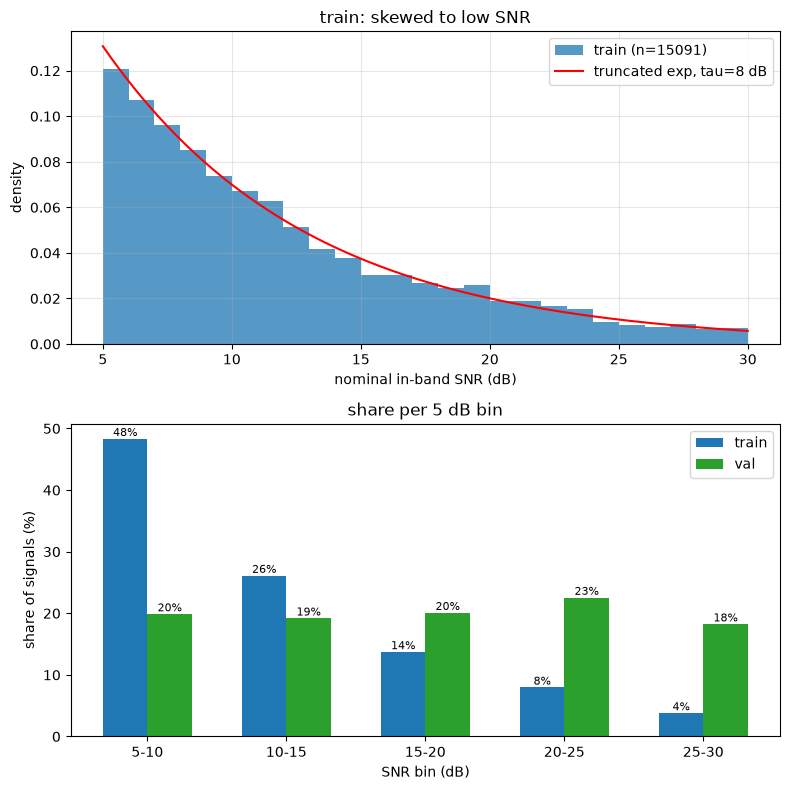

train n= 15091  mean=11.89 dB  median=10.23 dB  below 15 dB: 74.5 %
val   n=  3218  mean=17.49 dB  median=17.67 dB  below 15 dB: 39.1 %


In [4]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path("dataset_boost/spectrum_rf_v0.2.0_pilot/sets")   # change to the dataset you want to inspect
SNR_LO, SNR_HI, TAU = 5.0, 30.0, 8.0                              # CFG.snr_range, CFG.snr_tau_train (dB)

snr = {name: pd.read_parquet(DATA_DIR / name / "signals.parquet").snr_db.to_numpy() for name in ("train", "val")}

# theoretical densities
xs = np.linspace(SNR_LO, SNR_HI, 500)
pdf_trunc_exp = np.exp(-(xs - SNR_LO) / TAU) / (TAU * (1 - np.exp(-(SNR_HI - SNR_LO) / TAU)))

edges = np.arange(SNR_LO, SNR_HI + 1, 1.0)                        # 1 dB bins
fig, ax = plt.subplots(2, 1, figsize=(8, 8))

ax[0].hist(snr["train"], bins=edges, density=True, color="tab:blue", alpha=0.75, label=f"train (n={len(snr['train'])})")
ax[0].plot(xs, pdf_trunc_exp, "r-", lw=1.5, label=f"truncated exp, tau={TAU:g} dB")
ax[0].set(xlabel="nominal in-band SNR (dB)", ylabel="density", title="train: skewed to low SNR")
ax[0].legend()

bins5 = np.arange(SNR_LO, SNR_HI + 1, 5.0)
w = 1.6
for i, (name, c) in enumerate((("train", "tab:blue"), ("val", "tab:green"))):
    share = 100 * np.histogram(snr[name], bins=bins5)[0] / len(snr[name])
    bars = ax[1].bar(bins5[:-1] + 2.5 + (i - 0.5) * w, share, width=w, color=c, label=name)
    ax[1].bar_label(bars, fmt="%.0f%%", fontsize=8)
ax[1].set(xlabel="SNR bin (dB)", ylabel="share of signals (%)", title="share per 5 dB bin", xticks=bins5[:-1] + 2.5,
          xticklabels=[f"{a:.0f}-{a+5:.0f}" for a in bins5[:-1]])
ax[1].legend()
ax[0].grid(alpha=0.3)
plt.tight_layout()
plt.show()

for name in ("train", "val"):
    s = snr[name]
    print(f"{name:5s} n={len(s):6d}  mean={s.mean():5.2f} dB  median={np.median(s):5.2f} dB  below 15 dB: {100*np.mean(s < 15):.1f} %")